<a href="https://colab.research.google.com/github/Niseta701/Tech400/blob/main/week%207.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q numpy pandas matplotlib scikit-learn scipy

In [ ]:

from google.colab import files
import zipfile
import os

# Upload the ZIP file containing the CISI dataset
uploaded = files.upload()

# Extract the uploaded ZIP file
zip_file = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_file is None:
    raise ValueError("Please upload the CISI dataset as a ZIP file.")

extract_dir = "/content/cisi_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

# Locate the three required CISI files
required_files = ["CISI.ALL", "CISI.QRY", "CISI.REL"]
file_paths = {}

for required in required_files:
    matches = []

    for root, dirs, filenames in os.walk(extract_dir):
        for filename in filenames:
            if filename.upper() == required:
                matches.append(os.path.join(root, filename))

    if not matches:
        raise FileNotFoundError(
            f"{required} was not found. Check your ZIP file."
        )

    file_paths[required] = matches[0]

print("Dataset files found:")
for name, path in file_paths.items():
    print(name, "->", path)


Saving archive (6).zip to archive (6).zip
Dataset files found:
CISI.ALL -> /content/cisi_dataset/CISI.ALL
CISI.QRY -> /content/cisi_dataset/CISI.QRY
CISI.REL -> /content/cisi_dataset/CISI.REL


In [ ]:

import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Parse CISI documents and queries
def parse_cisi_file(file_path):
    records = {}
    current_id = None
    current_field = None

    with open(file_path, "r", encoding="latin-1") as f:
        for raw_line in f:
            line = raw_line.rstrip()

            # Start a new record
            if line.startswith(".I"):
                match = re.match(r"\.I\s+(\d+)", line)
                if match:
                    current_id = int(match.group(1))
                    records[current_id] = {
                        "title": "",
                        "text": ""
                    }
                    current_field = None

            elif current_id is not None and line.startswith(".T"):
                current_field = "title"

            elif current_id is not None and line.startswith(".W"):
                current_field = "text"

            elif current_id is not None and line.startswith(
                (".A", ".B", ".N", ".X", ".K")
            ):
                current_field = None

            elif current_id is not None and current_field:
                records[current_id][current_field] += " " + line

    for record in records.values():
        record["title"] = record["title"].strip()
        record["text"] = (
            record["title"] + " " + record["text"]
        ).strip()

    return records


# Load documents and queries
documents = parse_cisi_file(file_paths["CISI.ALL"])
query_records = parse_cisi_file(file_paths["CISI.QRY"])

queries = {
    query_id: record["text"]
    for query_id, record in query_records.items()
}

# Load CISI relevance file
# The original CISI.REL contains query ID, document ID,
# relevance rank, and a similarity/relevance value.
relevance = {}

with open(file_paths["CISI.REL"], "r", encoding="latin-1") as f:
    for line in f:
        parts = line.split()

        if len(parts) >= 2:
            try:
                query_id = int(parts[0])
                doc_id = int(parts[1])
            except ValueError:
                continue

            relevance.setdefault(query_id, set()).add(doc_id)

# Show dataset information
print("Documents loaded:", len(documents))
print("Queries loaded:", len(queries))
print("Queries with relevance judgments:", len(relevance))
print("Total relevance pairs:", sum(len(v) for v in relevance.values()))

print("\nFirst 10 query IDs:", list(queries.keys())[:10])
print("First 10 relevance query IDs:", list(relevance.keys())[:10])

# Verify that query IDs overlap
matching_ids = set(queries.keys()) & set(relevance.keys())
print("Matching query IDs:", len(matching_ids))

if not matching_ids:
    print("\nCheck the actual files being read:")
    for name, path in file_paths.items():
        print(f"\n{name}: {path}")
        with open(path, "r", encoding="latin-1") as f:
            for _ in range(5):
                print(repr(f.readline()))


Documents loaded: 1460
Queries loaded: 112
Queries with relevance judgments: 76
Total relevance pairs: 3114

First 10 query IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
First 10 relevance query IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Matching query IDs: 76


In [ ]:

# Create a consistent document ID order
doc_ids = sorted(documents.keys())
doc_texts = [documents[doc_id]["text"] for doc_id in doc_ids]

# Convert documents into TF-IDF vectors
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_df=0.95
)

document_matrix = tfidf_vectorizer.fit_transform(doc_texts)

# Convert queries into vectors using the same vocabulary
query_ids = sorted(queries.keys())
query_texts = [queries[qid] for qid in query_ids]
query_matrix = tfidf_vectorizer.transform(query_texts)

# Cosine similarity measures the similarity of query and document vectors
tfidf_similarity = cosine_similarity(
    query_matrix, document_matrix
)

print("TF-IDF model is ready.")
print("Document matrix shape:", document_matrix.shape)
print("Query matrix shape:", query_matrix.shape)


TF-IDF model is ready.
Document matrix shape: (1460, 87044)
Query matrix shape: (112, 87044)


In [ ]:

from collections import Counter

def tokenize(text):
    return re.findall(r"\b[a-z0-9]+\b", text.lower())


# Tokenize documents and calculate document lengths
tokenized_documents = [
    tokenize(documents[doc_id]["text"])
    for doc_id in doc_ids
]

document_lengths = np.array(
    [len(tokens) for tokens in tokenized_documents]
)

average_length = (
    document_lengths.mean() if len(document_lengths) else 0
)

term_frequencies = [
    Counter(tokens) for tokens in tokenized_documents
]

# Document frequency for each term
document_frequency = Counter()

for frequencies in term_frequencies:
    document_frequency.update(frequencies.keys())

N = len(doc_ids)
k1 = 1.5
b = 0.75


def bm25_search(query, top_k=10):
    query_terms = tokenize(query)
    scores = np.zeros(N, dtype=float)

    for term in query_terms:
        df = document_frequency.get(term, 0)

        if df == 0:
            continue

        # BM25 inverse document frequency
        idf = math.log(
            1 + (N - df + 0.5) / (df + 0.5)
        )

        for index, frequencies in enumerate(term_frequencies):
            tf = frequencies.get(term, 0)

            if tf == 0:
                continue

            doc_length = document_lengths[index]

            length_norm = (
                1 - b + b * doc_length / average_length
                if average_length > 0 else 1
            )

            scores[index] += idf * (
                tf * (k1 + 1)
            ) / (
                tf + k1 * length_norm
            )

    ranked_indices = np.argsort(scores)[::-1][:top_k]

    return [
        (doc_ids[index], float(scores[index]))
        for index in ranked_indices
        if scores[index] > 0
    ]


def tfidf_search(query_index, top_k=10):
    scores = tfidf_similarity[query_index]
    ranked_indices = np.argsort(scores)[::-1][:top_k]

    return [
        (doc_ids[index], float(scores[index]))
        for index in ranked_indices
        if scores[index] > 0
    ]


print("BM25 model is ready.")


BM25 model is ready.


In [ ]:

K = 10

def precision_at_k(ranked_ids, relevant_ids, k=K):
    if k == 0:
        return 0.0

    retrieved = ranked_ids[:k]
    return sum(doc_id in relevant_ids for doc_id in retrieved) / k


def recall_at_k(ranked_ids, relevant_ids, k=K):
    if not relevant_ids:
        return 0.0

    retrieved = ranked_ids[:k]
    hits = sum(doc_id in relevant_ids for doc_id in retrieved)

    return hits / len(relevant_ids)


def average_precision_at_k(ranked_ids, relevant_ids, k=K):
    if not relevant_ids:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for rank, doc_id in enumerate(ranked_ids[:k], start=1):
        if doc_id in relevant_ids:
            hits += 1
            precision_sum += hits / rank

    # AP at K normalized by the maximum possible relevant hits in top K
    return precision_sum / min(len(relevant_ids), k)


def ndcg_at_k(ranked_ids, relevant_ids, k=K):
    dcg = 0.0

    for rank, doc_id in enumerate(ranked_ids[:k], start=1):
        if doc_id in relevant_ids:
            dcg += 1.0 / math.log2(rank + 1)

    ideal_hits = min(len(relevant_ids), k)

    idcg = sum(
        1.0 / math.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else 0.0


print("Precision@10, Recall@10, AP@10 and nDCG@10 are defined.")


Precision@10, Recall@10, AP@10 and nDCG@10 are defined.


In [ ]:

# CELL 7: Evaluate TF-IDF and BM25 models

results = []
query_level_results = []
top_query_results = []

for query_index, query_id in enumerate(query_ids):
    relevant_ids = relevance.get(query_id, set())

    # Skip queries without relevance judgments
    if not relevant_ids:
        continue

    rankings = {
        "TF-IDF": tfidf_search(query_index, K),
        "BM25": bm25_search(queries[query_id], K)
    }

    for model_name, ranked_results in rankings.items():
        ranked_ids = [doc_id for doc_id, score in ranked_results]

        row = {
            "Query ID": query_id,
            "Model": model_name,
            "Precision@10": precision_at_k(ranked_ids, relevant_ids, K),
            "Recall@10": recall_at_k(ranked_ids, relevant_ids, K),
            "AP@10": average_precision_at_k(ranked_ids, relevant_ids, K),
            "nDCG@10": ndcg_at_k(ranked_ids, relevant_ids, K)
        }

        query_level_results.append(row)

        # Save the top 10 results for query 1
        if query_id == 1:
            for rank, (doc_id, score) in enumerate(
                ranked_results, start=1
            ):
                top_query_results.append({
                    "Query ID": query_id,
                    "Model": model_name,
                    "Rank": rank,
                    "Document ID": doc_id,
                    "Title": documents[doc_id]["title"],
                    "Score": score,
                    "Relevant": doc_id in relevant_ids
                })

# Create DataFrames
query_metrics = pd.DataFrame(
    query_level_results,
    columns=[
        "Query ID", "Model", "Precision@10", "Recall@10",
        "AP@10", "nDCG@10"
    ]
)

# Check that the evaluation produced results
if query_metrics.empty:
    print("No evaluation results were generated.")
    print("Queries loaded:", len(queries))
    print("Queries with relevance judgments:", len(relevance))
    print("Example query IDs:", list(queries.keys())[:10])
    print("Example relevance query IDs:", list(relevance.keys())[:10])
    raise ValueError(
        "No matching queries and relevance judgments. "
        "Check Cell 3 and confirm CISI.REL was parsed correctly."
    )

# Average metrics for each retrieval model
summary = (
    query_metrics.groupby("Model")[
        ["Precision@10", "Recall@10", "AP@10", "nDCG@10"]
    ]
    .mean()
    .reset_index()
    .round(4)
)

print("AVERAGE MODEL PERFORMANCE")
display(summary)

print("QUERY-LEVEL METRICS")
display(query_metrics.head(10))

print("TOP RESULTS FOR QUERY 1")
display(pd.DataFrame(top_query_results))


AVERAGE MODEL PERFORMANCE


,Model,Precision@10,Recall@10,AP@10,nDCG@10
0,BM25,0.2987,0.1213,0.2200,0.3496
1,TF-IDF,0.3013,0.1233,0.2031,0.3231


QUERY-LEVEL METRICS


,Query ID,Model,Precision@10,Recall@10,AP@10,nDCG@10
0,1,TF-IDF,0.7,0.152174,0.673214,0.791727
1,1,BM25,0.8,0.173913,0.645873,0.804811
2,2,TF-IDF,0.0,0.000000,0.000000,0.000000
3,2,BM25,0.0,0.000000,0.000000,0.000000
4,3,TF-IDF,0.9,0.204545,0.866389,0.926636
5,3,BM25,0.3,0.068182,0.216667,0.408536
6,4,TF-IDF,0.1,0.125000,0.012500,0.073117
7,4,BM25,0.2,0.250000,0.066667,0.187952
8,5,TF-IDF,0.1,0.041667,0.033333,0.110046
9,5,BM25,0.2,0.083333,0.061905,0.183410


TOP RESULTS FOR QUERY 1


,Query ID,Model,Rank,Document ID,Title,Score,Relevant
0,1,TF-IDF,1,722,Information Transfer Limitations of Titles of ...,0.197408,True
1,1,TF-IDF,2,589,Are Titles of Chemical Papers Becoming More In...,0.146371,True
2,1,TF-IDF,3,429,The Information Content of Titles in Engineeri...,0.143468,True
3,1,TF-IDF,4,813,"Comparative Efficiency of Searching Titles, Ab...",0.133190,True
4,1,TF-IDF,5,1281,Relative Effectiveness of Document Titles and ...,0.130882,True
5,1,TF-IDF,6,1299,Current Physics Information,0.108576,False
6,1,TF-IDF,7,650,"Relative Effectiveness of Titles, Abstracts, a...",0.100000,True
7,1,TF-IDF,8,711,"Development and Production of Chemical Titles,...",0.090249,True
8,1,TF-IDF,9,219,Selected Lists of Journals for the Small Medic...,0.089273,False
9,1,TF-IDF,10,447,"A Note on the Concept of ""Relevance""",0.088407,False


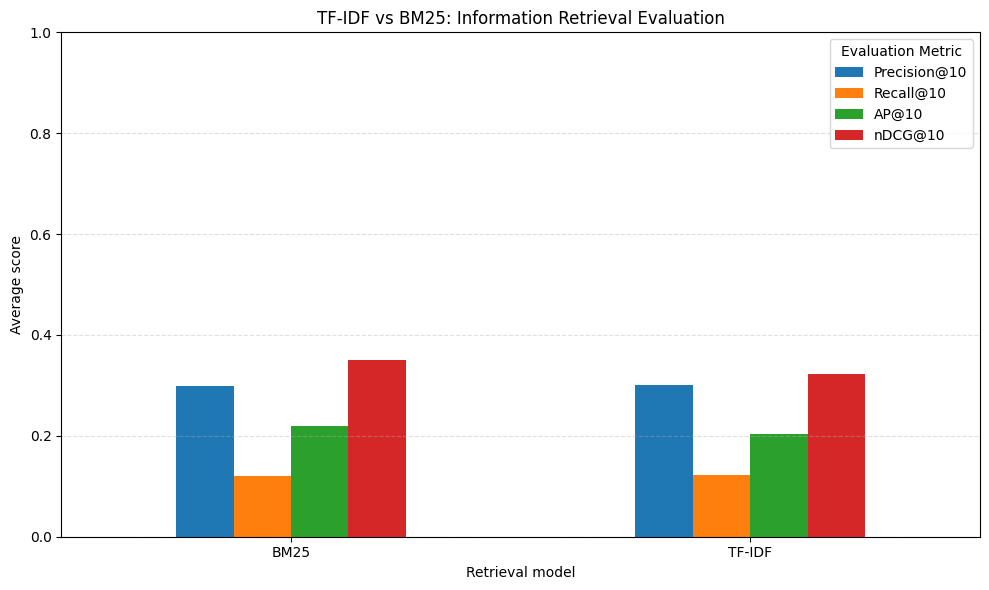

In [ ]:

# Plot the average performance of TF-IDF and BM25
plot_data = summary.set_index("Model")

plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("TF-IDF vs BM25: Information Retrieval Evaluation")
plt.ylabel("Average score")
plt.xlabel("Retrieval model")
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


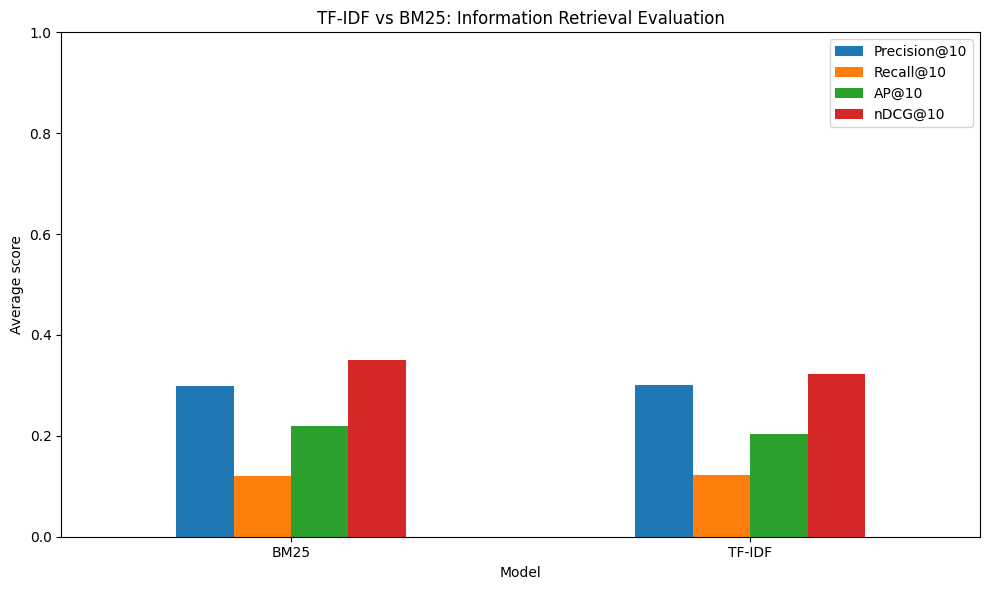

Files saved:
1. model_comparison.csv
2. query_level_metrics.csv
3. top10_query1.csv
4. model_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Save results as CSV files
summary.to_csv("/content/model_comparison.csv", index=False)
query_metrics.to_csv("/content/query_level_metrics.csv", index=False)

pd.DataFrame(top_query_results).to_csv(
    "/content/top10_query1.csv", index=False
)

# Save the chart
fig = plt.figure(figsize=(10, 6))
plot_data.plot(kind="bar", ylim=(0, 1), rot=0, ax=plt.gca())
plt.title("TF-IDF vs BM25: Information Retrieval Evaluation")
plt.ylabel("Average score")
plt.tight_layout()
plt.savefig("/content/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Files saved:")
print("1. model_comparison.csv")
print("2. query_level_metrics.csv")
print("3. top10_query1.csv")
print("4. model_comparison.png")

# Download each output file to your computer
from google.colab import files

files.download("/content/model_comparison.csv")
files.download("/content/query_level_metrics.csv")
files.download("/content/top10_query1.csv")
files.download("/content/model_comparison.png")


Upload cisi_dataset.zip containing CISI.ALL, CISI.QRY and CISI.REL


Saving archive (6).zip to archive (6).zip

Dataset files found:
/content/cisi_dataset/CISI.ALL
/content/cisi_dataset/CISI.QRY
/content/cisi_dataset/CISI.REL

Number of documents: 1460
Number of queries: 112
Queries with relevance judgments: 76
Total relevance judgments: 3114
Evaluating TF-IDF...
Evaluating BM25-set...
Evaluating BM25-weighted...
Evaluating LM-JM-0.1...
Evaluating LM-JM-0.7...
Evaluating Random...

================ OVERALL RESULTS ================



,P@1,P@5,P@10,P@20,R@10,R@100,F1@10,Success@10,MAP,MRR,R-precision,nDCG@5,nDCG@10,nDCG@20
Model,,,,,,,,,,,,,,
BM25-weighted,0.5395,0.4053,0.3263,0.2592,0.1320,0.4394,0.1555,0.8816,0.2156,0.6596,0.2315,0.4416,0.3831,0.3472
LM-JM-0.7,0.4737,0.3816,0.3237,0.2520,0.1315,0.4255,0.1551,0.8947,0.2029,0.6087,0.2245,0.4105,0.3681,0.3293
TF-IDF,0.4211,0.3447,0.2961,0.2382,0.1237,0.4299,0.1436,0.8421,0.2019,0.5844,0.2237,0.3759,0.3397,0.3135
LM-JM-0.1,0.4605,0.3395,0.3000,0.2355,0.1283,0.4085,0.1395,0.8816,0.1736,0.5873,0.1974,0.3631,0.3351,0.3001
BM25-set,0.4474,0.3000,0.2724,0.2309,0.1203,0.3949,0.1289,0.8947,0.1683,0.5741,0.1923,0.3298,0.3073,0.2890
Random,0.0263,0.0211,0.0237,0.0230,0.0097,0.0643,0.0115,0.2368,0.0331,0.0887,0.0258,0.0220,0.0240,0.0256



================ BOOTSTRAP CONFIDENCE INTERVALS ================



,Model,Metric,Mean,CI_2.5%,CI_97.5%
0,BM25-weighted,MAP,0.2156,0.1752,0.2544
1,BM25-weighted,MRR,0.6596,0.5719,0.7424
2,BM25-weighted,P@10,0.3263,0.2776,0.3750
3,BM25-weighted,R@10,0.1320,0.0985,0.1709
4,BM25-weighted,nDCG@10,0.3831,0.3267,0.4387
5,LM-JM-0.7,MAP,0.2029,0.1688,0.2439
6,LM-JM-0.7,MRR,0.6087,0.5191,0.6977
7,LM-JM-0.7,P@10,0.3237,0.2671,0.3724
8,LM-JM-0.7,R@10,0.1315,0.0994,0.1692
9,LM-JM-0.7,nDCG@10,0.3681,0.3135,0.4222



================ PAIRED TESTS ================



,Reference_Model,Compared_Model,Metric,Paired_t_statistic,p_value,Queries_Compared,Holm_adjusted_p,Significant_0.05
0,BM25-weighted,LM-JM-0.7,MAP,4.81372,0.00001,76,0.00003,True
1,BM25-weighted,TF-IDF,MAP,1.99198,0.05001,76,0.05001,False
2,BM25-weighted,LM-JM-0.1,MAP,3.22114,0.00189,76,0.00378,True
3,BM25-weighted,BM25-set,MAP,4.03554,0.00013,76,0.00039,True
4,BM25-weighted,Random,MAP,9.00872,0.00000,76,0.00000,True



================ QUERY LENGTH ANALYSIS ================



,Model,Short_Query_MAP,Long_Query_MAP,Average_Query_Length,Evaluated_Queries
0,BM25-set,0.1379,0.1723,36.0526,76.0
1,BM25-weighted,0.1518,0.2242,36.0526,76.0
2,LM-JM-0.1,0.1350,0.1788,36.0526,76.0
3,LM-JM-0.7,0.1405,0.2112,36.0526,76.0
4,Random,0.0449,0.0315,36.0526,76.0
5,TF-IDF,0.1592,0.2077,36.0526,76.0


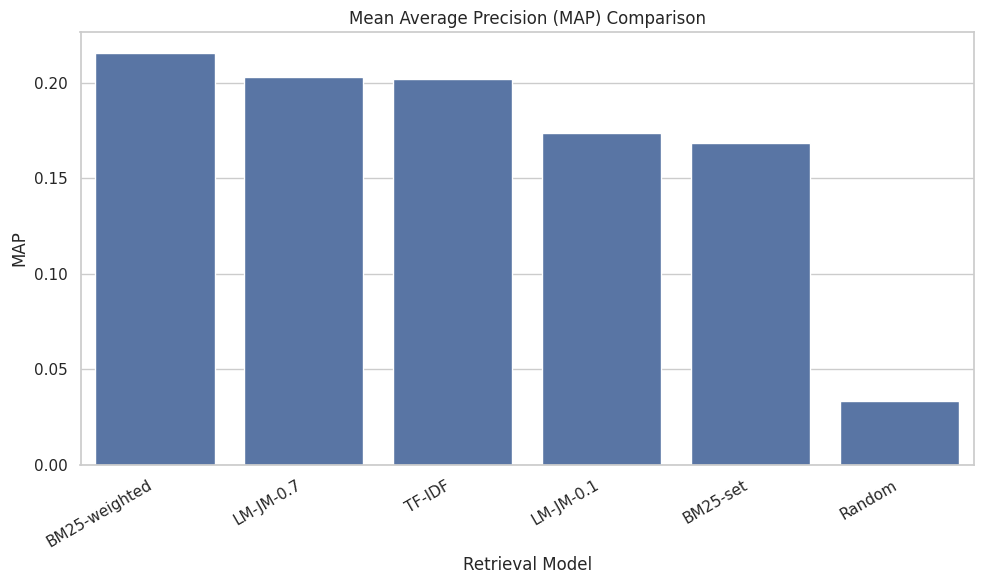

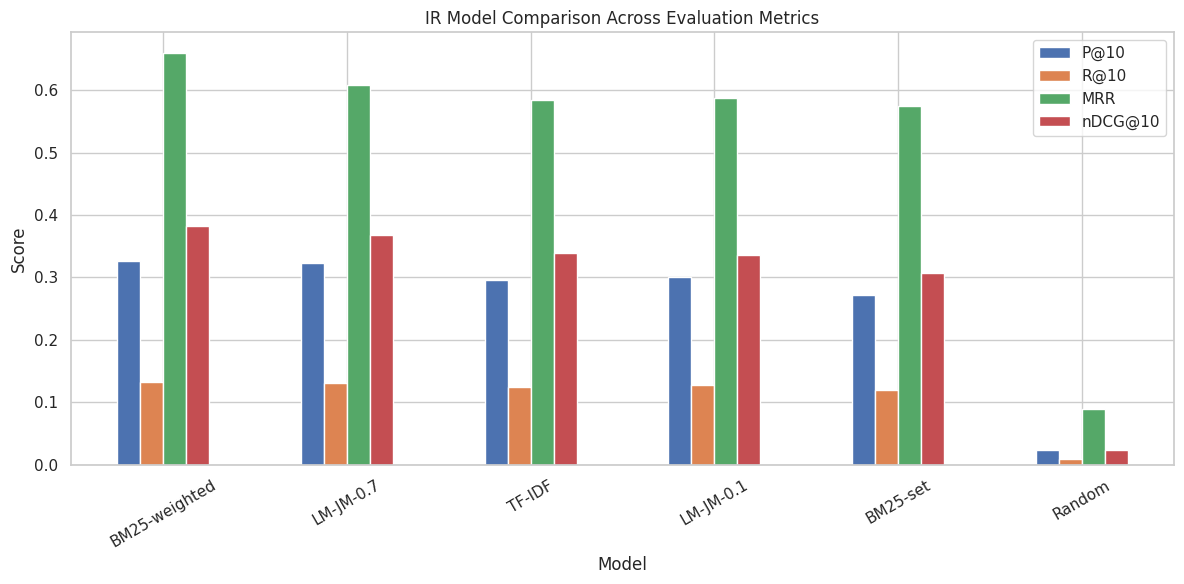

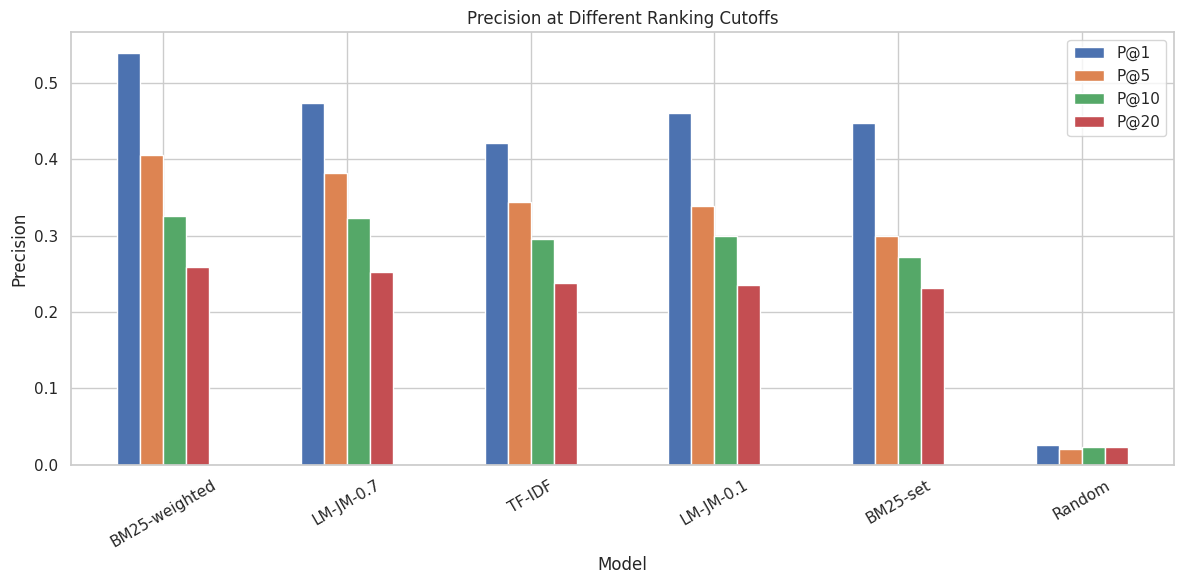

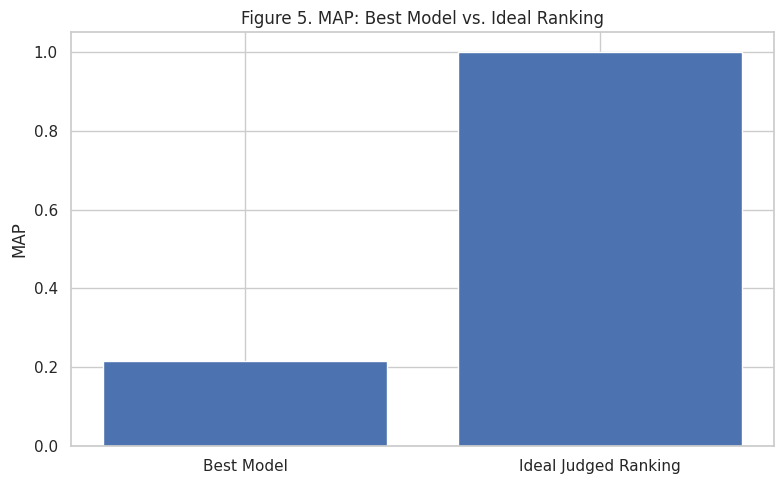

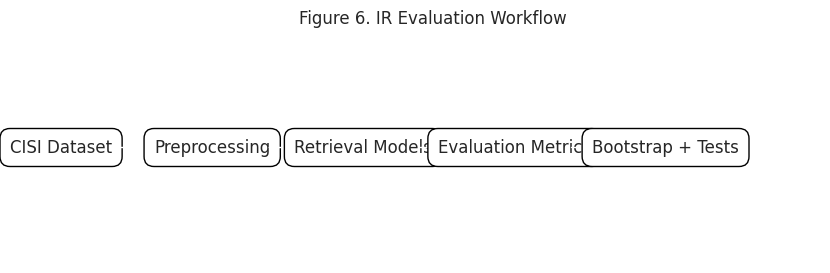

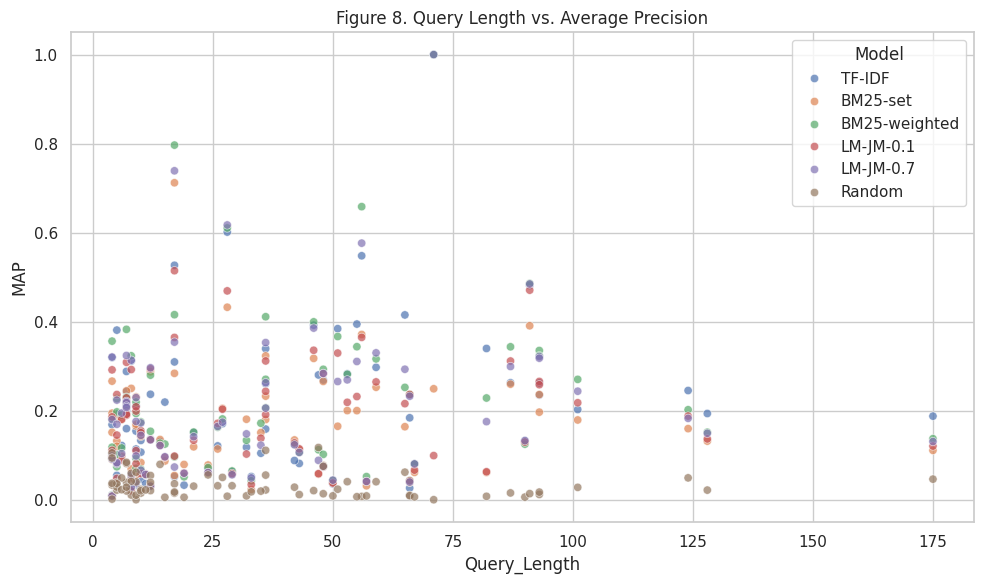

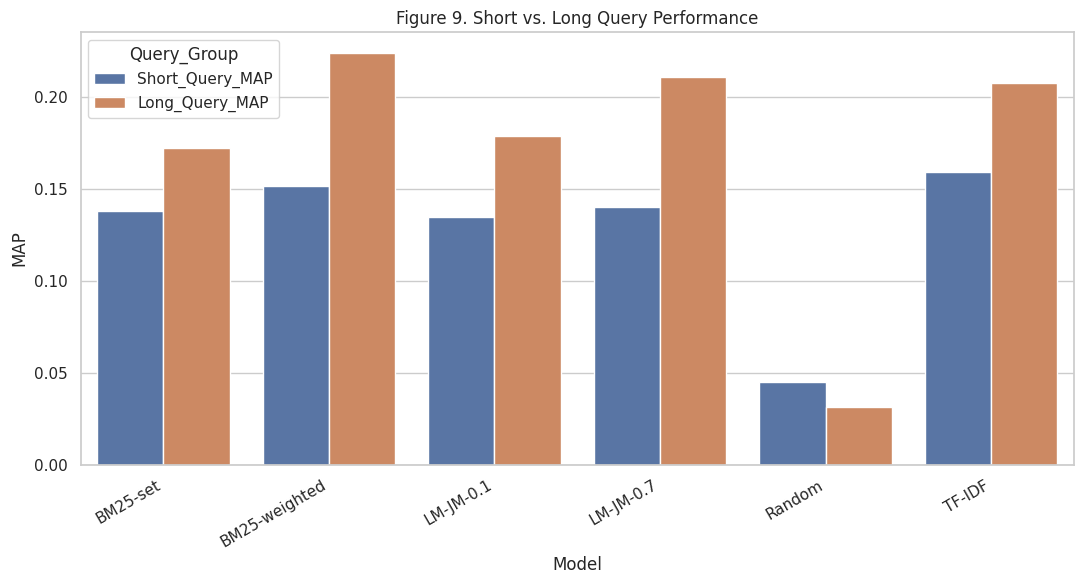

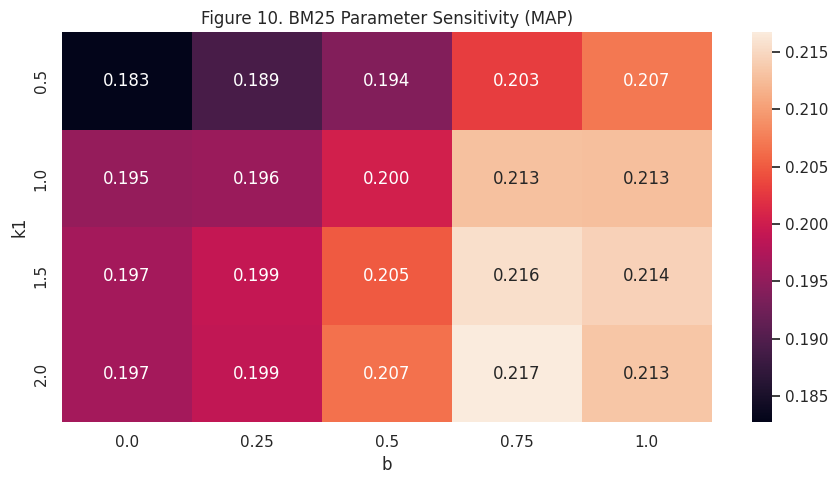

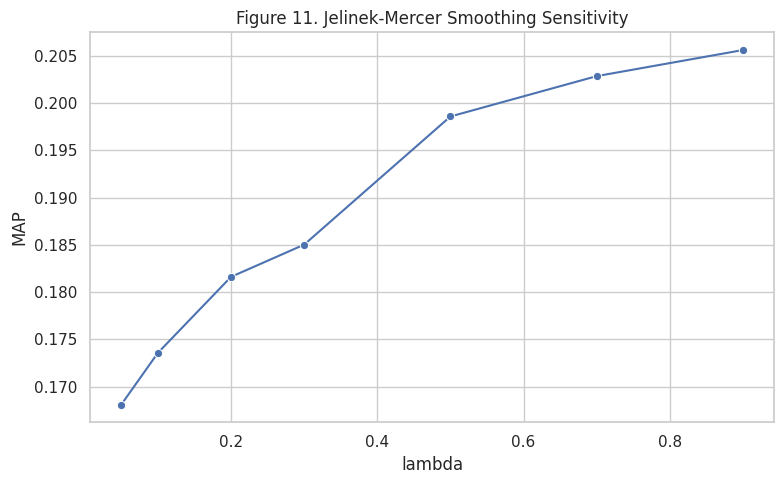


EVALUATION COMPLETED

Dataset summary:


,Documents,Queries,Queries_With_Relevance,Total_Relevance_Judgments,Evaluated_Queries,Models
0,1460,112,76,3114,76,6



Overall model ranking by MAP:


,MAP,MRR,P@10,R@10,nDCG@10
Model,,,,,
BM25-weighted,0.2156,0.6596,0.3263,0.1320,0.3831
LM-JM-0.7,0.2029,0.6087,0.3237,0.1315,0.3681
TF-IDF,0.2019,0.5844,0.2961,0.1237,0.3397
LM-JM-0.1,0.1736,0.5873,0.3000,0.1283,0.3351
BM25-set,0.1683,0.5741,0.2724,0.1203,0.3073
Random,0.0331,0.0887,0.0237,0.0097,0.0240



Output files:
bm25_parameter_sensitivity.csv
bootstrap_confidence_intervals.csv
dataset_summary.csv
figure10_bm25_sensitivity.png
figure11_jm_smoothing.png
figure5_oracle_ceiling.png
figure6_statistical_workflow.png
figure8_query_length_vs_map.png
figure9_short_long_queries.png
jm_smoothing_sensitivity.csv
map_comparison.png
metric_comparison.png
overall_results.csv
per_query_results.csv
query_length_analysis.csv
ranking_metrics.png
statistical_tests.csv
top10_ranked_documents.csv



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CISI INFORMATION RETRIEVAL EVALUATION - GOOGLE COLAB
# One-cell version
# Models: Random, TF-IDF, BM25, Language Models (Jelinek-Mercer)
# Metrics: P@K, Recall, F1, MAP, MRR, R-Precision, nDCG
# Outputs: CSV reports, graphs, statistical comparisons, ZIP
# ============================================================

!pip -q install numpy pandas matplotlib seaborn scikit-learn scipy

import os
import re
import zipfile
import shutil
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_rel, permutation_test
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from google.colab import files

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# -------------------- 1. UPLOAD DATASET --------------------

print("Upload cisi_dataset.zip containing CISI.ALL, CISI.QRY and CISI.REL")
uploaded = files.upload()

zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_files:
    raise ValueError(
        "Please upload a ZIP file containing CISI.ALL, CISI.QRY, and CISI.REL."
    )

DATA_DIR = Path("/content/cisi_dataset")
OUTPUT_DIR = Path("/content/results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_files[0], "r") as z:
    z.extractall(DATA_DIR)

def locate_file(filename):
    matches = list(DATA_DIR.rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"{filename} not found. Ensure it is inside the uploaded ZIP."
        )
    return matches[0]

ALL_FILE = locate_file("CISI.ALL")
QRY_FILE = locate_file("CISI.QRY")
REL_FILE = locate_file("CISI.REL")

print("\nDataset files found:")
print(ALL_FILE)
print(QRY_FILE)
print(REL_FILE)

# -------------------- 2. PARSE CISI FILES --------------------

def parse_cisi(path, marker):
    """Parse CISI files separated by .I document/query IDs and field markers."""
    records = {}
    current_id = None
    current_field = None
    buffer = []

    def save_field():
        if current_id is not None and current_field is not None:
            value = " ".join(buffer).strip()
            records[current_id][current_field] = (
                records[current_id].get(current_field, "") + " " + value
            ).strip()

    with open(path, "r", encoding="latin-1") as f:
        for raw_line in f:
            line = raw_line.rstrip("\n\r")

            if line.startswith(".I "):
                save_field()
                parts = line.split()
                current_id = int(parts[1])
                records[current_id] = {}
                current_field = None
                buffer = []

            elif line.startswith(".") and len(line) >= 2 and line[1].isalpha():
                save_field()
                current_field = line[1]
                buffer = []

            elif current_id is not None:
                buffer.append(line.strip())

        save_field()

    output = {}
    for record_id, fields in records.items():
        if marker == "document":
            text = " ".join(
                fields.get(k, "") for k in ["T", "A", "B", "W"]
            ).strip()
        else:
            text = " ".join(
                fields.get(k, "") for k in ["T", "W"]
            ).strip()

        output[record_id] = text

    return output

documents = parse_cisi(ALL_FILE, "document")
queries = parse_cisi(QRY_FILE, "query")

print(f"\nNumber of documents: {len(documents)}")
print(f"Number of queries: {len(queries)}")

# -------------------- 3. LOAD RELEVANCE JUDGMENTS --------------------

def load_relevance(path):
    """
    Standard CISI.REL format contains query ID and document ID.
    Treat every listed query-document pair as relevant.
    """
    relevance = defaultdict(set)

    with open(path, "r", encoding="latin-1") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue

            parts = line.split()
            try:
                qid = int(parts[0])
                docid = int(parts[1])
                relevance[qid].add(docid)
            except (ValueError, IndexError):
                continue

    return dict(relevance)

qrels = load_relevance(REL_FILE)
print(f"Queries with relevance judgments: {len(qrels)}")
print(f"Total relevance judgments: {sum(len(v) for v in qrels.values())}")

# -------------------- 4. PREPROCESSING --------------------

try:
    import nltk
    from nltk.corpus import stopwords
    nltk.download("stopwords", quiet=True)
    STOPWORDS = set(stopwords.words("english"))
except Exception:
    STOPWORDS = set()

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    tokens = re.findall(r"\b[a-z0-9]+\b", text)
    tokens = [
        token for token in tokens
        if token not in STOPWORDS and len(token) > 1
    ]
    return " ".join(tokens)

doc_ids = sorted(documents)
query_ids = sorted(queries)

raw_docs = [documents[d] for d in doc_ids]
processed_docs = [preprocess(documents[d]) for d in doc_ids]
processed_queries = {
    qid: preprocess(queries[qid]) for qid in query_ids
}
doc_index = {doc_id: i for i, doc_id in enumerate(doc_ids)}

# -------------------- 5. TF-IDF MODEL --------------------

vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

tfidf_matrix = vectorizer.fit_transform(processed_docs)
query_matrix = vectorizer.transform(
    [processed_queries[qid] for qid in query_ids]
)
tfidf_scores = cosine_similarity(query_matrix, tfidf_matrix)

# -------------------- 6. BM25 MODELS --------------------

def build_bm25(corpus, queries_text, k1=1.5, b=0.75):
    """Build BM25 scores from tokenized text."""
    tokenized_docs = [text.split() for text in corpus]
    N = len(tokenized_docs)
    doc_lengths = np.array([len(doc) for doc in tokenized_docs], dtype=float)
    avgdl = doc_lengths.mean() if N else 1.0

    df = defaultdict(int)
    term_frequencies = []

    for tokens in tokenized_docs:
        tf = defaultdict(int)
        for token in tokens:
            tf[token] += 1
        term_frequencies.append(tf)
        for token in tf:
            df[token] += 1

    idf = {
        term: np.log(1 + (N - frequency + 0.5) / (frequency + 0.5))
        for term, frequency in df.items()
    }

    score_matrix = np.zeros((len(queries_text), N), dtype=float)

    for qi, query in enumerate(queries_text):
        query_terms = query.split()
        for di, tf in enumerate(term_frequencies):
            length_norm = k1 * (
                1 - b + b * doc_lengths[di] / (avgdl if avgdl else 1)
            )
            score = 0.0
            for term in query_terms:
                freq = tf.get(term, 0)
                if freq:
                    score += idf.get(term, 0) * (
                        freq * (k1 + 1) / (freq + length_norm)
                    )
            score_matrix[qi, di] = score

    return score_matrix

query_texts = [processed_queries[qid] for qid in query_ids]
bm25_weighted_scores = build_bm25(processed_docs, query_texts)

# BM25-set: BM25 with binary document term presence
binary_docs = [
    " ".join(set(text.split())) for text in processed_docs
]
bm25_set_scores = build_bm25(
    binary_docs, query_texts, k1=1.0, b=0.0
)

# -------------------- 7. JELINEK-MERCER LANGUAGE MODELS --------------------

def build_jm(corpus, queries_text, lam=0.1):
    """Query likelihood with Jelinek-Mercer smoothing."""
    tokenized_docs = [text.split() for text in corpus]
    collection_tf = defaultdict(int)
    total_collection_terms = 0

    for tokens in tokenized_docs:
        for token in tokens:
            collection_tf[token] += 1
            total_collection_terms += 1

    collection_size = max(total_collection_terms, 1)
    scores = np.zeros((len(queries_text), len(tokenized_docs)), dtype=float)

    for di, tokens in enumerate(tokenized_docs):
        tf = defaultdict(int)
        for token in tokens:
            tf[token] += 1
        length = max(len(tokens), 1)

        for qi, query in enumerate(queries_text):
            score = 0.0
            for term in query.split():
                p_collection = collection_tf.get(term, 0) / collection_size
                p_document = tf.get(term, 0) / length
                probability = (
                    (1 - lam) * p_document + lam * p_collection
                )
                score += np.log(max(probability, 1e-12))
            scores[qi, di] = score

    return scores

jm_01_scores = build_jm(processed_docs, query_texts, lam=0.1)
jm_07_scores = build_jm(processed_docs, query_texts, lam=0.7)

# -------------------- 8. RANK DOCUMENTS --------------------

models = {
    "TF-IDF": tfidf_scores,
    "BM25-set": bm25_set_scores,
    "BM25-weighted": bm25_weighted_scores,
    "LM-JM-0.1": jm_01_scores,
    "LM-JM-0.7": jm_07_scores,
}

random_scores = np.random.RandomState(RANDOM_SEED).random(
    (len(query_ids), len(doc_ids))
)
models["Random"] = random_scores

def ranked_doc_ids(score_row):
    order = np.argsort(-score_row)
    return [doc_ids[i] for i in order]

# -------------------- 9. EVALUATION METRICS --------------------

def precision_at_k(ranked, relevant, k):
    if k <= 0:
        return 0.0
    return sum(d in relevant for d in ranked[:k]) / k

def recall_at_k(ranked, relevant, k):
    if not relevant:
        return 0.0
    return sum(d in relevant for d in ranked[:k]) / len(relevant)

def average_precision(ranked, relevant):
    if not relevant:
        return 0.0
    hits = 0
    total_precision = 0.0
    for rank, docid in enumerate(ranked, start=1):
        if docid in relevant:
            hits += 1
            total_precision += hits / rank
    return total_precision / len(relevant)

def reciprocal_rank(ranked, relevant):
    for rank, docid in enumerate(ranked, start=1):
        if docid in relevant:
            return 1.0 / rank
    return 0.0

def r_precision(ranked, relevant):
    R = len(relevant)
    if R == 0:
        return 0.0
    return sum(d in relevant for d in ranked[:R]) / R

def ndcg_at_k(ranked, relevant, k):
    gains = [1 if d in relevant else 0 for d in ranked[:k]]
    dcg = sum(
        gain / np.log2(rank + 1)
        for rank, gain in enumerate(gains, start=1)
    )
    ideal_hits = min(len(relevant), k)
    ideal_dcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / ideal_dcg if ideal_dcg else 0.0

def evaluate_one(ranked, relevant):
    p10 = precision_at_k(ranked, relevant, 10)
    r10 = recall_at_k(ranked, relevant, 10)
    f1 = (2 * p10 * r10 / (p10 + r10)) if (p10 + r10) else 0.0

    return {
        "P@1": precision_at_k(ranked, relevant, 1),
        "P@5": precision_at_k(ranked, relevant, 5),
        "P@10": p10,
        "P@20": precision_at_k(ranked, relevant, 20),
        "R@10": r10,
        "R@100": recall_at_k(ranked, relevant, 100),
        "F1@10": f1,
        "Success@10": float(any(d in relevant for d in ranked[:10])),
        "MAP": average_precision(ranked, relevant),
        "MRR": reciprocal_rank(ranked, relevant),
        "R-precision": r_precision(ranked, relevant),
        "nDCG@5": ndcg_at_k(ranked, relevant, 5),
        "nDCG@10": ndcg_at_k(ranked, relevant, 10),
        "nDCG@20": ndcg_at_k(ranked, relevant, 20),
    }

per_query_rows = []
rankings = {}

for model_name, score_matrix in models.items():
    print(f"Evaluating {model_name}...")
    for qi, qid in enumerate(query_ids):
        ranked = ranked_doc_ids(score_matrix[qi])
        rankings[(model_name, qid)] = ranked
        relevant = qrels.get(qid, set())

        if not relevant:
            continue

        metric_values = evaluate_one(ranked, relevant)
        per_query_rows.append({
            "Model": model_name,
            "Query_ID": qid,
            "Query_Length": len(processed_queries[qid].split()),
            "Relevant_Documents": len(relevant),
            **metric_values
        })

per_query_df = pd.DataFrame(per_query_rows)

if per_query_df.empty:
    raise ValueError(
        "No evaluated queries have relevance judgments. Check the CISI.REL format."
    )

metric_columns = [
    "P@1", "P@5", "P@10", "P@20", "R@10", "R@100",
    "F1@10", "Success@10", "MAP", "MRR", "R-precision",
    "nDCG@5", "nDCG@10", "nDCG@20"
]

overall_df = (
    per_query_df.groupby("Model")[metric_columns]
    .mean()
    .sort_values("MAP", ascending=False)
)

per_query_df.to_csv(OUTPUT_DIR / "per_query_results.csv", index=False)
overall_df.to_csv(OUTPUT_DIR / "overall_results.csv")

print("\n================ OVERALL RESULTS ================\n")
display(overall_df.round(4))

# -------------------- 10. BOOTSTRAP CONFIDENCE INTERVALS --------------------

bootstrap_rows = []
rng = np.random.default_rng(RANDOM_SEED)
n_bootstrap = 1000

for model_name in overall_df.index:
    model_df = per_query_df[per_query_df["Model"] == model_name]

    for metric in ["MAP", "MRR", "P@10", "R@10", "nDCG@10"]:
        values = model_df[metric].dropna().to_numpy()
        if len(values) == 0:
            continue

        boot_means = [
            np.mean(rng.choice(values, size=len(values), replace=True))
            for _ in range(n_bootstrap)
        ]

        bootstrap_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean": np.mean(values),
            "CI_2.5%": np.percentile(boot_means, 2.5),
            "CI_97.5%": np.percentile(boot_means, 97.5)
        })

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals.csv", index=False
)

print("\n================ BOOTSTRAP CONFIDENCE INTERVALS ================\n")
display(bootstrap_df.round(4))

# -------------------- 11. PAIRED STATISTICAL TESTS --------------------

# Compare each retrieval model against the best MAP model.
best_model = overall_df["MAP"].idxmax()
test_rows = []

best_query_scores = (
    per_query_df[per_query_df["Model"] == best_model]
    .set_index("Query_ID")["MAP"]
)

for model_name in overall_df.index:
    if model_name == best_model:
        continue

    other_query_scores = (
        per_query_df[per_query_df["Model"] == model_name]
        .set_index("Query_ID")["MAP"]
    )

    common = best_query_scores.index.intersection(other_query_scores.index)
    a = best_query_scores.loc[common].to_numpy()
    b = other_query_scores.loc[common].to_numpy()

    if len(a) < 2:
        p_value = np.nan
        t_stat = np.nan
    else:
        result = ttest_rel(a, b, nan_policy="omit")
        t_stat = result.statistic
        p_value = result.pvalue

    test_rows.append({
        "Reference_Model": best_model,
        "Compared_Model": model_name,
        "Metric": "MAP",
        "Paired_t_statistic": t_stat,
        "p_value": p_value,
        "Queries_Compared": len(a)
    })

tests_df = pd.DataFrame(test_rows)

# Holm correction for multiple comparisons
if not tests_df.empty:
    valid = tests_df["p_value"].notna()
    pvals = tests_df.loc[valid, "p_value"].to_numpy()
    order = np.argsort(pvals)
    adjusted = np.empty(len(pvals))
    running_max = 0.0
    m = len(pvals)

    for rank, idx in enumerate(order):
        corrected = min(1.0, (m - rank) * pvals[idx])
        running_max = max(running_max, corrected)
        adjusted[idx] = running_max

    tests_df["Holm_adjusted_p"] = np.nan
    tests_df.loc[valid, "Holm_adjusted_p"] = adjusted
    tests_df["Significant_0.05"] = (
        tests_df["Holm_adjusted_p"] < 0.05
    )

tests_df.to_csv(OUTPUT_DIR / "statistical_tests.csv", index=False)

print("\n================ PAIRED TESTS ================\n")
display(tests_df.round(5))

# -------------------- 12. QUERY LENGTH ANALYSIS --------------------

query_analysis = (
    per_query_df.groupby("Model")
    .apply(
        lambda group: pd.Series({
            "Short_Query_MAP": group.loc[
                group["Query_Length"] <= 5, "MAP"
            ].mean(),
            "Long_Query_MAP": group.loc[
                group["Query_Length"] > 5, "MAP"
            ].mean(),
            "Average_Query_Length": group["Query_Length"].mean(),
            "Evaluated_Queries": group["Query_ID"].nunique()
        }),
        include_groups=False
    )
    .reset_index()
)

query_analysis.to_csv(
    OUTPUT_DIR / "query_length_analysis.csv", index=False
)

print("\n================ QUERY LENGTH ANALYSIS ================\n")
display(query_analysis.round(4))

# -------------------- 13. PLOTS --------------------

sns.set_theme(style="whitegrid")

# Figure 1: MAP comparison
plt.figure(figsize=(10, 6))
plot_data = overall_df["MAP"].sort_values(ascending=False)
sns.barplot(x=plot_data.index, y=plot_data.values)
plt.title("Mean Average Precision (MAP) Comparison")
plt.xlabel("Retrieval Model")
plt.ylabel("MAP")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "map_comparison.png", dpi=200)
plt.show()

# Figure 2: Precision, recall and ranking metrics
selected_metrics = ["P@10", "R@10", "MRR", "nDCG@10"]
overall_df[selected_metrics].plot(
    kind="bar", figsize=(12, 6), rot=30
)
plt.title("IR Model Comparison Across Evaluation Metrics")
plt.ylabel("Score")
plt.xlabel("Model")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metric_comparison.png", dpi=200)
plt.show()

# Figure 3: Precision at K
pk_metrics = ["P@1", "P@5", "P@10", "P@20"]
overall_df[pk_metrics].plot(
    kind="bar", figsize=(12, 6), rot=30
)
plt.title("Precision at Different Ranking Cutoffs")
plt.ylabel("Precision")
plt.xlabel("Model")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ranking_metrics.png", dpi=200)
plt.show()

# Figure 5: Oracle ceiling illustration
# Ideal ranking places all judged-relevant documents before non-relevant ones.
oracle_rows = []
for qid in query_ids:
    relevant = qrels.get(qid, set())
    if not relevant:
        continue
    ideal_ranking = list(relevant) + [
        d for d in doc_ids if d not in relevant
    ]
    oracle_rows.append(evaluate_one(ideal_ranking, relevant))

if oracle_rows:
    oracle_map = np.mean([row["MAP"] for row in oracle_rows])
    oracle_ndcg = np.mean([row["nDCG@10"] for row in oracle_rows])
    best_map = overall_df["MAP"].max()
    best_ndcg = overall_df["nDCG@10"].max()

    plt.figure(figsize=(8, 5))
    labels = ["Best Model", "Ideal Judged Ranking"]
    plt.bar(labels, [best_map, oracle_map])
    plt.title("Figure 5. MAP: Best Model vs. Ideal Ranking")
    plt.ylabel("MAP")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figure5_oracle_ceiling.png", dpi=200)
    plt.show()

# Figure 6: Statistical workflow diagram
plt.figure(figsize=(10, 3))
plt.axis("off")
workflow = [
    "CISI Dataset",
    "Preprocessing",
    "Retrieval Models",
    "Evaluation Metrics",
    "Bootstrap + Tests"
]
for i, label in enumerate(workflow):
    x = 0.02 + i * 0.195
    plt.text(
        x, 0.5, label, ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.6", facecolor="white",
                  edgecolor="black"),
        transform=plt.gca().transAxes
    )
    if i < len(workflow) - 1:
        plt.annotate(
            "", xy=(x + 0.13, 0.5), xytext=(x + 0.07, 0.5),
            xycoords=plt.gca().transAxes,
            arrowprops=dict(arrowstyle="->")
        )
plt.title("Figure 6. IR Evaluation Workflow")
plt.savefig(OUTPUT_DIR / "figure6_statistical_workflow.png", dpi=200,
            bbox_inches="tight")
plt.show()

# Figure 8: Query length vs MAP for models
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=per_query_df, x="Query_Length", y="MAP",
    hue="Model", alpha=0.7
)
plt.title("Figure 8. Query Length vs. Average Precision")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure8_query_length_vs_map.png", dpi=200)
plt.show()

# Figure 9: Short vs long query MAP
if not query_analysis.empty:
    qlong = query_analysis.melt(
        id_vars="Model",
        value_vars=["Short_Query_MAP", "Long_Query_MAP"],
        var_name="Query_Group", value_name="MAP"
    )
    plt.figure(figsize=(11, 6))
    sns.barplot(data=qlong, x="Model", y="MAP", hue="Query_Group")
    plt.title("Figure 9. Short vs. Long Query Performance")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figure9_short_long_queries.png", dpi=200)
    plt.show()

# Figure 10: BM25 parameter sensitivity
bm25_grid = []
for k1 in [0.5, 1.0, 1.5, 2.0]:
    for b in [0.0, 0.25, 0.5, 0.75, 1.0]:
        scores = build_bm25(
            processed_docs, query_texts, k1=k1, b=b
        )
        aps = []
        for qi, qid in enumerate(query_ids):
            relevant = qrels.get(qid, set())
            if relevant:
                aps.append(
                    average_precision(
                        ranked_doc_ids(scores[qi]), relevant
                    )
                )
        bm25_grid.append({
            "k1": k1, "b": b,
            "MAP": np.mean(aps) if aps else 0
        })

bm25_grid_df = pd.DataFrame(bm25_grid)
bm25_grid_df.to_csv(OUTPUT_DIR / "bm25_parameter_sensitivity.csv",
                    index=False)
heatmap = bm25_grid_df.pivot(index="k1", columns="b", values="MAP")
plt.figure(figsize=(9, 5))
sns.heatmap(heatmap, annot=True, fmt=".3f")
plt.title("Figure 10. BM25 Parameter Sensitivity (MAP)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure10_bm25_sensitivity.png", dpi=200)
plt.show()

# Figure 11: Jelinek-Mercer smoothing sensitivity
jm_grid = []
for lam in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]:
    scores = build_jm(processed_docs, query_texts, lam=lam)
    aps = []
    for qi, qid in enumerate(query_ids):
        relevant = qrels.get(qid, set())
        if relevant:
            aps.append(
                average_precision(
                    ranked_doc_ids(scores[qi]), relevant
                )
            )
    jm_grid.append({
        "lambda": lam,
        "MAP": np.mean(aps) if aps else 0
    })

jm_grid_df = pd.DataFrame(jm_grid)
jm_grid_df.to_csv(OUTPUT_DIR / "jm_smoothing_sensitivity.csv",
                  index=False)
plt.figure(figsize=(8, 5))
sns.lineplot(data=jm_grid_df, x="lambda", y="MAP", marker="o")
plt.title("Figure 11. Jelinek-Mercer Smoothing Sensitivity")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure11_jm_smoothing.png", dpi=200)
plt.show()

# -------------------- 14. SAVE TOP RESULTS --------------------

top_rows = []
for model_name, score_matrix in models.items():
    for qi, qid in enumerate(query_ids):
        ranked = ranked_doc_ids(score_matrix[qi])
        for rank, docid in enumerate(ranked[:10], start=1):
            top_rows.append({
                "Model": model_name,
                "Query_ID": qid,
                "Rank": rank,
                "Document_ID": docid,
                "Relevant": int(docid in qrels.get(qid, set()))
            })

top10_df = pd.DataFrame(top_rows)
top10_df.to_csv(OUTPUT_DIR / "top10_ranked_documents.csv", index=False)

# Save dataset summary
summary = pd.DataFrame([{
    "Documents": len(documents),
    "Queries": len(queries),
    "Queries_With_Relevance": len(qrels),
    "Total_Relevance_Judgments": sum(len(v) for v in qrels.values()),
    "Evaluated_Queries": per_query_df["Query_ID"].nunique(),
    "Models": len(models)
}])
summary.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)

# -------------------- 15. DOWNLOAD OUTPUTS --------------------

zip_path = shutil.make_archive(
    "/content/CISI_IR_Evaluation_Results",
    "zip",
    root_dir=OUTPUT_DIR
)

print("\n===================================================")
print("EVALUATION COMPLETED")
print("===================================================")
print("\nDataset summary:")
display(summary)

print("\nOverall model ranking by MAP:")
display(overall_df[["MAP", "MRR", "P@10", "R@10", "nDCG@10"]].round(4))

print("\nOutput files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)

print("\nDownloading all reports and graphs as a ZIP...")
files.download(zip_path)
